In [1]:
import sqlite3
import pandas as pd

con = sqlite3.connect("../data/pgh311.db")
df = pd.read_sql("SELECT * FROM model_data", con)
df.shape

(46875, 4)

In [2]:
# 1. Overall 30-day closure rate (should be ~0.727)
df["closed_within_30d"].mean()

np.float64(0.726976)

In [3]:
# 2. Quick structure check: 88 neighborhoods, 8 subjects, only 0s and 1s
print(df["neighborhood"].nunique(), "neighborhoods")
print(df["subject"].nunique(), "subjects")
print(df["closed_within_30d"].value_counts())

88 neighborhoods
8 subjects
closed_within_30d
1    34077
0    12798
Name: count, dtype: int64


In [4]:
# 3. Closure rate and count by subject, slowest first
by_subject = (
    df.groupby("subject")["closed_within_30d"]
      .agg(rate="mean", n="size")
      .sort_values("rate")
)
by_subject["rate"] = (by_subject["rate"] * 100).round(1)
by_subject

,rate,n
subject,,
City Tree Maintenance,31.6,3202
Overgrowth,35.5,3040
Street Light Concerns,55.1,4894
Potholes,60.2,9121
Litter on Public Property,60.8,3473
Street Cleaning/Sweeping,62.0,1955
Repair or Replace a Sign,87.4,3115
Missed Pick Up,98.2,18075


In [5]:
# 4. Gap between the fastest and slowest service, in percentage points
by_subject["rate"].max() - by_subject["rate"].min()

np.float64(66.6)

In [6]:
df["neighborhood"].value_counts().head()

neighborhood
Squirrel Hill South    1952
Brookline              1950
Carrick                1821
Bloomfield             1609
Shadyside              1578
Name: count, dtype: int64

In [7]:
import numpy as np
import statsmodels.formula.api as smf

model = smf.logit(
    "closed_within_30d ~ C(neighborhood, Treatment(reference='Squirrel Hill South')) + C(subject)",
    data=df
).fit()

Optimization terminated successfully.
         Current function value: 0.408384
         Iterations 8


In [8]:
odds_ratios = np.exp(model.params)
odds_ratios[odds_ratios.index.str.contains("subject")]

C(subject)[T.Litter on Public Property]      3.091444
C(subject)[T.Missed Pick Up]               127.306980
C(subject)[T.Overgrowth]                     1.041822
C(subject)[T.Potholes]                       3.782565
C(subject)[T.Repair or Replace a Sign]      16.181019
C(subject)[T.Street Cleaning/Sweeping]       4.033342
C(subject)[T.Street Light Concerns]          2.699196
dtype: float64

In [9]:
# Neighborhood odds ratios with 95% confidence intervals
is_nbhd = model.params.index.str.contains("neighborhood")
ci = model.conf_int()                       # columns 0 (lower) and 1 (upper), on the log-odds scale

nbhd_or = pd.DataFrame({
    "odds_ratio": np.exp(model.params[is_nbhd]),
    "lower":      np.exp(ci.loc[is_nbhd, 0]),
    "upper":      np.exp(ci.loc[is_nbhd, 1]),
})

# Tidy the row names: "C(neighborhood, ...)[T.Bloomfield]" -> "Bloomfield"
nbhd_or.index = nbhd_or.index.str.extract(r"\[T\.(.+)\]", expand=False)

nbhd_or = nbhd_or.sort_values("odds_ratio")

# How many are clearly different from Squirrel Hill South?
below = (nbhd_or["upper"] < 1).sum()        # whole interval below 1 -> clearly slower
above = (nbhd_or["lower"] > 1).sum()        # whole interval above 1 -> clearly faster
print(f"Clearly slower: {below}, clearly faster: {above}, out of {len(nbhd_or)}")

nbhd_or.head(5).round(2)

Clearly slower: 7, clearly faster: 51, out of 87


,odds_ratio,lower,upper
Homewood West,0.55,0.37,0.82
Hays,0.68,0.44,1.04
Homewood North,0.68,0.51,0.91
East Hills,0.70,0.52,0.94
Polish Hill,0.74,0.55,0.99


In [10]:
model_avg = smf.logit(
    "closed_within_30d ~ C(neighborhood, Sum) + C(subject)",
    data=df
).fit()

Optimization terminated successfully.
         Current function value: 0.408384
         Iterations 8


In [11]:
is_nbhd = model_avg.params.index.str.contains("neighborhood")
res = pd.DataFrame({
    "log_odds": model_avg.params[is_nbhd],
    "se":       model_avg.bse[is_nbhd],
    "p":        model_avg.pvalues[is_nbhd],
})
res.index = res.index.str.extract(r"\[S\.(.+)\]", expand=False)

# Sum coding leaves one neighborhood out; its effect = minus the sum of the others
missing = sorted(set(df["neighborhood"]) - set(res.index))
contrast = np.zeros(len(model_avg.params))
contrast[is_nbhd] = -1
tt = model_avg.t_test(contrast)
res.loc[missing[0]] = [tt.effect.item(), tt.sd.item(), tt.pvalue.item()]

res["odds_ratio"] = np.exp(res["log_odds"])
res["lower"] = np.exp(res["log_odds"] - 1.96 * res["se"])
res["upper"] = np.exp(res["log_odds"] + 1.96 * res["se"])

In [12]:
from statsmodels.stats.multitest import multipletests

reject, p_adj, _, _ = multipletests(res["p"], alpha=0.05, method="fdr_bh")
res["p_adj"] = p_adj
res["significant"] = reject

slower = (res["significant"] & (res["odds_ratio"] < 1)).sum()
faster = (res["significant"] & (res["odds_ratio"] > 1)).sum()
print(f"Significant after correction: {slower} slower, {faster} faster, out of {len(res)}")

Significant after correction: 31 slower, 25 faster, out of 88


In [13]:
adjusted = {}
for nb in res.index:
    counterfactual = df.assign(neighborhood=nb)
    adjusted[nb] = model_avg.predict(counterfactual).mean()

res["adjusted_rate"] = (pd.Series(adjusted) * 100).round(1)
res.sort_values("adjusted_rate")[["adjusted_rate", "odds_ratio", "lower", "upper", "p_adj", "significant"]].head(10).round(3)

,adjusted_rate,odds_ratio,lower,upper,p_adj,significant
Homewood West,58.8,0.337,0.230,0.494,0.0,True
Hays,61.7,0.414,0.273,0.626,0.0,True
Homewood North,61.9,0.417,0.318,0.547,0.0,True
East Hills,62.2,0.427,0.323,0.565,0.0,True
Polish Hill,63.1,0.454,0.345,0.595,0.0,True
Upper Lawrenceville,63.1,0.455,0.352,0.588,0.0,True
New Homestead,63.4,0.464,0.329,0.654,0.0,True
Point Breeze,64.3,0.493,0.426,0.572,0.0,True
Bloomfield,64.6,0.505,0.446,0.571,0.0,True
Homewood South,64.6,0.504,0.376,0.674,0.0,True


In [14]:
adjusted = {}
for nb in res.index:
    counterfactual = df.assign(neighborhood=nb)
    adjusted[nb] = model_avg.predict(counterfactual).mean()

res["adjusted_rate"] = (pd.Series(adjusted) * 100).round(1)
res.sort_values("adjusted_rate")[["adjusted_rate", "odds_ratio", "lower", "upper", "p_adj", "significant"]].tail(10).round(3)

,adjusted_rate,odds_ratio,lower,upper,p_adj,significant
Esplen,83.8,2.099,1.052,4.190,0.055,False
Allegheny Center,84.2,2.190,1.391,3.448,0.002,True
East Carnegie,84.3,2.197,1.155,4.179,0.026,True
Manchester,84.3,2.203,1.607,3.022,0.000,True
California-Kirkbride,84.4,2.229,1.342,3.700,0.004,True
Perry North,84.7,2.275,1.738,2.978,0.000,True
Troy Hill,84.7,2.286,1.712,3.053,0.000,True
Perry South,85.5,2.454,1.941,3.102,0.000,True
East Allegheny,86.5,2.727,2.078,3.578,0.000,True
Northview Heights,87.8,3.121,1.515,6.429,0.004,True


In [15]:
districts = pd.read_sql("""
    SELECT neighborhood, council_district AS main_district
    FROM (
        SELECT neighborhood,
               council_district,
               COUNT(*) AS n,
               ROW_NUMBER() OVER (PARTITION BY neighborhood ORDER BY COUNT(*) DESC) AS rank_in_nbhd
        FROM in_scope
        GROUP BY neighborhood, council_district
    )
    WHERE rank_in_nbhd = 1
      AND neighborhood IN (SELECT DISTINCT neighborhood FROM model_data)
""", con)

In [16]:
res = res.join(districts.set_index("neighborhood"))
res["n_requests"] = df["neighborhood"].value_counts()

print(res["main_district"].isna().sum(), "neighborhoods missing a district")   # should be 0

0 neighborhoods missing a district


In [17]:
import os
os.makedirs("../results", exist_ok=True)
res.sort_values("adjusted_rate").to_csv("../results/neighborhood_results.csv", index_label="neighborhood")

In [18]:
res.groupby("main_district")["adjusted_rate"].agg(["median", "min", "max", "count"]).sort_values("median")

,median,min,max,count
main_district,,,,
D9,64.9,58.8,70.3,10
D7,66.7,63.1,83.8,9
D8,67.9,66.2,68.5,3
D5,68.8,61.7,71.5,9
D6,73.2,65.1,85.5,13
D3,74.5,66.8,78.1,9
D4,75.0,74.4,80.4,5
D2,80.4,71.3,84.3,16
D1,82.8,74.1,87.8,14


## Robustness check: 14-day window instead of 30
Does the district ranking depend on choosing 30 days? Refit with a 14-day outcome (view `model_data_14d`, see `sql/03_results.sql`) and compare.

In [20]:
df14 = pd.read_sql("SELECT * FROM model_data_14d", con)
print(df14.shape, round(df14["closed_within_14d"].mean(), 3))

m14 = smf.logit("closed_within_14d ~ C(neighborhood, Sum) + C(subject)", data=df14).fit()

adj14 = {nb: m14.predict(df14.assign(neighborhood=nb)).mean() for nb in res.index}
res["adjusted_rate_14d"] = (pd.Series(adj14) * 100).round(1)

# Do neighborhoods rank the same way under both windows? (1.0 = identical order)
print("Rank correlation:", round(res["adjusted_rate"].corr(res["adjusted_rate_14d"], method="spearman"), 3))

res.groupby("main_district")[["adjusted_rate", "adjusted_rate_14d"]].median().sort_values("adjusted_rate")

(46875, 4) 0.62
Optimization terminated successfully.
         Current function value: 0.462169
         Iterations 7
Rank correlation: 0.906


,adjusted_rate,adjusted_rate_14d
main_district,,
D9,64.9,54.5
D7,66.7,54.0
D8,67.9,56.1
D5,68.8,58.8
D6,73.2,55.5
D3,74.5,66.0
D4,75.0,66.1
D2,80.4,68.7
D1,82.8,72.8


In [21]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

FIG_DIR = "../figures"
os.makedirs(FIG_DIR, exist_ok=True)

INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"     # text: primary, secondary, muted
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"  # hairlines and background
BLUE = "#2a78d6"                                       # the one data color
CITYWIDE = 72.7                                        # % closed within 30 days, all of model_data

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.edgecolor": AXIS, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
})

def add_titles(fig, title, subtitle):
    fig.text(0.01, 0.985, title, ha="left", va="top", fontsize=13.5, fontweight="bold", color=INK)
    fig.text(0.01, 0.925, subtitle, ha="left", va="top", fontsize=9.5, color=INK2)

Matplotlib is building the font cache; this may take a moment.


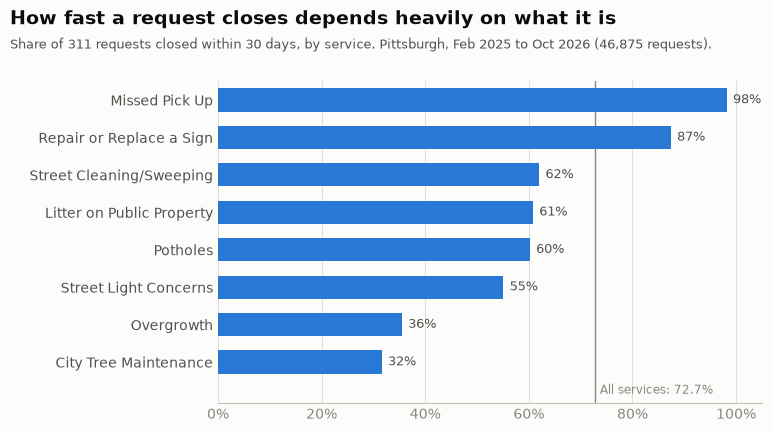

In [22]:
s = by_subject.sort_values("rate")               # ascending, so the fastest bar ends up on top
fig, ax = plt.subplots(figsize=(8, 4.6))
fig.subplots_adjust(left=0.27, right=0.95, top=0.83, bottom=0.13)

ax.barh(s.index, s["rate"], color=BLUE, height=0.62)
for y, v in enumerate(s["rate"]):
    ax.text(v + 1.2, y, f"{v:.0f}%", va="center", fontsize=9, color=INK2)

ax.axvline(CITYWIDE, color=MUTED, lw=1, zorder=0)
ax.text(CITYWIDE + 1, -0.75, f"All services: {CITYWIDE}%", fontsize=8.5, color=MUTED, va="center")

ax.set_xlim(0, 105)
ax.set_ylim(-1.1, len(s) - 0.5)
ax.set_xticks(range(0, 101, 20))
ax.set_xticklabels([f"{t}%" for t in range(0, 101, 20)])
ax.xaxis.grid(True, color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="both", length=0)

add_titles(fig, "How fast a request closes depends heavily on what it is",
           "Share of 311 requests closed within 30 days, by service. Pittsburgh, Feb 2025 to Oct 2026 (46,875 requests).")
fig.savefig(f"{FIG_DIR}/01_closure_by_service.png", dpi=200)

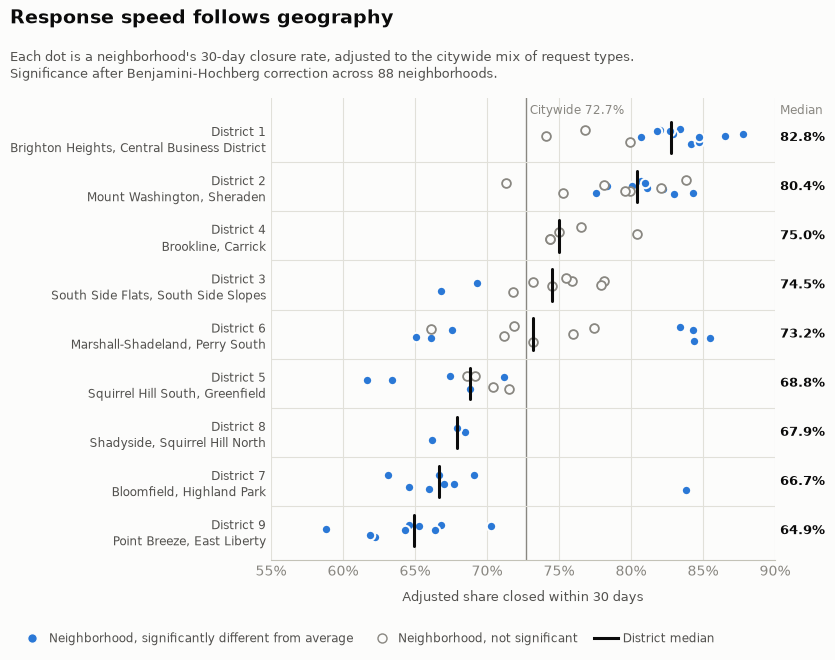

In [25]:
res.index.name = "neighborhood"
medians = res.groupby("main_district")["adjusted_rate"].median().sort_values()   # fastest district ends up on top
ypos = {d: i for i, d in enumerate(medians.index)}

# Name each district by its two neighborhoods with the most requests
examples = (res.sort_values("n_requests", ascending=False)
               .groupby("main_district").head(2)
               .reset_index()
               .groupby("main_district")["neighborhood"].apply(", ".join))
labels = [f"District {d[1:]}\n{examples[d]}" for d in medians.index]

rng = np.random.default_rng(311)                       # fixed seed: same jitter every run
y = res["main_district"].map(ypos) + rng.uniform(-0.18, 0.18, len(res))

fig, ax = plt.subplots(figsize=(9, 6.6))
fig.subplots_adjust(left=0.30, right=0.86, top=0.85, bottom=0.15)

sig = res["significant"]
ax.scatter(res.loc[sig, "adjusted_rate"], y[sig], s=46, color=BLUE,
           edgecolor=SURFACE, linewidth=1.5, zorder=3)
ax.scatter(res.loc[~sig, "adjusted_rate"], y[~sig], s=40, facecolor=SURFACE,
           edgecolor=MUTED, linewidth=1.3, zorder=3)

for d, m in medians.items():
    ax.plot([m, m], [ypos[d] - 0.32, ypos[d] + 0.32], color=INK, lw=2.2, zorder=4, solid_capstyle="round")
    ax.text(1.01, ypos[d], f"{m:.1f}%", transform=ax.get_yaxis_transform(),
            va="center", fontsize=9.5, color=INK, fontweight="bold")
ax.text(1.01, len(medians) - 0.45, "Median", transform=ax.get_yaxis_transform(),
        va="center", fontsize=8.5, color=MUTED)

ax.axvline(CITYWIDE, color=MUTED, lw=1, zorder=0)
ax.text(CITYWIDE, len(medians) - 0.45, f" Citywide {CITYWIDE}%", fontsize=8.5, color=MUTED, va="center")

ax.set_yticks(range(len(medians)))
ax.set_yticklabels(labels, fontsize=8.8, linespacing=1.4)
ax.set_ylim(-0.6, len(medians) - 0.2)
ax.set_xlim(55, 90)
ax.set_xticks(range(55, 91, 5))
ax.set_xticklabels([f"{t}%" for t in range(55, 91, 5)])
ax.xaxis.grid(True, color=GRID, lw=0.8)
for i in range(len(medians) - 1):
    ax.axhline(i + 0.5, color=GRID, lw=0.8, zorder=0)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.tick_params(length=0)
ax.set_xlabel("Adjusted share closed within 30 days", fontsize=9.5, labelpad=8)

legend = [
    Line2D([], [], marker="o", ls="", markersize=7, markerfacecolor=BLUE, markeredgecolor=SURFACE,
           label="Neighborhood, significantly different from average"),
    Line2D([], [], marker="o", ls="", markersize=6.5, markerfacecolor=SURFACE, markeredgecolor=MUTED,
           label="Neighborhood, not significant"),
    Line2D([], [], color=INK, lw=2.2, label="District median"),
]
fig.legend(handles=legend, loc="lower left", bbox_to_anchor=(0.01, 0.005), ncol=3,
           frameon=False, fontsize=8.5, labelcolor=INK2, handletextpad=0.4, columnspacing=1.4)

add_titles(fig, "Response speed follows geography",
           "Each dot is a neighborhood's 30-day closure rate, adjusted to the citywide mix of request types.\n"
           "Significance after Benjamini-Hochberg correction across 88 neighborhoods.")
fig.savefig(f"{FIG_DIR}/02_adjusted_rate_by_district.png", dpi=200)

In [26]:
res.sort_values("adjusted_rate").to_csv("../results/neighborhood_results.csv", index_label="neighborhood")